In [19]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import matplotlib.pyplot as plt
from IPython import display
import seaborn as sns

import time
import numpy as np

from scipy.stats import norm, multivariate_normal
from scipy.optimize import brentq
from scipy import stats

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Effect of $a$ on $VaR_\alpha(Z)$ where $Z = X+Y$:

If marginals are independent: $a$ vector changes the mean contribution from each marginal, variance is same.

If marginals are positively correlated:
$$
a_1.a_2 > 0: \text{ variance}; \qquad
a_1.a_2 < 0: \text{ variance}; 
$$

If marginals are negatively correlated:
$$
a_1.a_2 > 0: \text{ variance}; \qquad
a_1.a_2 < 0: \text{ variance}; 
$$

In [69]:
rng = np.random.default_rng(0); d_max = 1000
m = np.array([10, 15]); s = [1.7, 0.5]
alpha = 0.9; eps = 1 - alpha; rho = 0.5

cov_eq = lambda s, r: np.outer(s, s) * (np.full((len(s), len(s)), r) + (1 - r)*np.eye(len(s))) #sd_i sd_j rho

def VaR_gauss(d, a):
    mu_Z = a @ m
    f = lambda r: mu_Z + norm.ppf(eps) * np.sqrt(max(a @ cov_eq(s, r) @ a, 0))
    return f(-1), f(0.), f(rho), f(1.)  #W-like, Pi, rho, M

In [70]:
d = 2
a = [[1, 0], [1, 1], [0, 1], [-1,0], [0,-1], [-1,-1], [-1, 1] , [1, -1], [0, 0]]
for i in range(len(a)):
    v_neg, v_pi, v_rho, v_M = VaR_gauss(d, a[i])
    print(f"Vector {i}: {a[i]}| VaR: W {v_neg:.2f}| Pi {v_pi:.2f}| rho {v_rho:.2f}| M {v_M:.2f}")


Vector 0: [1, 0]| VaR: W 7.82| Pi 7.82| rho 7.82| M 7.82
Vector 1: [1, 1]| VaR: W 23.46| Pi 22.73| rho 22.44| M 22.18
Vector 2: [0, 1]| VaR: W 14.36| Pi 14.36| rho 14.36| M 14.36
Vector 3: [-1, 0]| VaR: W -12.18| Pi -12.18| rho -12.18| M -12.18
Vector 4: [0, -1]| VaR: W -15.64| Pi -15.64| rho -15.64| M -15.64
Vector 5: [-1, -1]| VaR: W -26.54| Pi -27.27| rho -27.56| M -27.82
Vector 6: [-1, 1]| VaR: W 2.18| Pi 2.73| rho 3.06| M 3.46
Vector 7: [1, -1]| VaR: W -7.82| Pi -7.27| rho -6.94| M -6.54
Vector 8: [0, 0]| VaR: W 0.00| Pi 0.00| rho 0.00| M 0.00


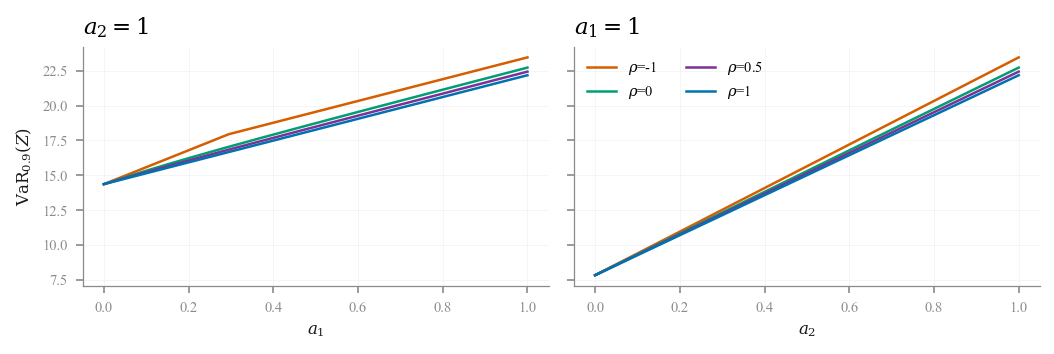

In [71]:
import library.matplotlib_style as ms
ms.use_paper()

ag = np.linspace(0, 1, 201); rhos = [-1, 0, 0.5, 1]
col = [ms.ROLE[k] for k in ('frechet', 'indep', 'rho', 'comon')]
var_lo = lambda a, r: np.asarray(a) @ m + norm.ppf(eps) * np.sqrt(max(np.asarray(a) @ cov_eq(s, r) @ np.asarray(a), 0)) #z_0.1 lower tail

fig, ax = plt.subplots(1, 2, figsize = (7, 2.4), sharey = True)
for i, r in enumerate(rhos):
    ax[0].plot(ag, [var_lo([x, 1], r) for x in ag], color = col[i], label = rf'$\rho$={r}')
    ax[1].plot(ag, [var_lo([1, x], r) for x in ag], color = col[i], label = rf'$\rho$={r}')

ms.style_axes(ax[0], xlabel = r'$a_1$', ylabel = r'$\mathrm{VaR}_{0.9}(Z)$', title = r'$a_2=1$', grid = 'both')
ms.style_axes(ax[1], xlabel = r'$a_2$', title = r'$a_1=1$', grid = 'both')
ax[1].legend(ncol = 2)
fig.tight_layout()

Text(0.01, 1.08, '$\\mathrm{VaR}_\\alpha(Z)$, lower tail, $\\rho$=0.5')

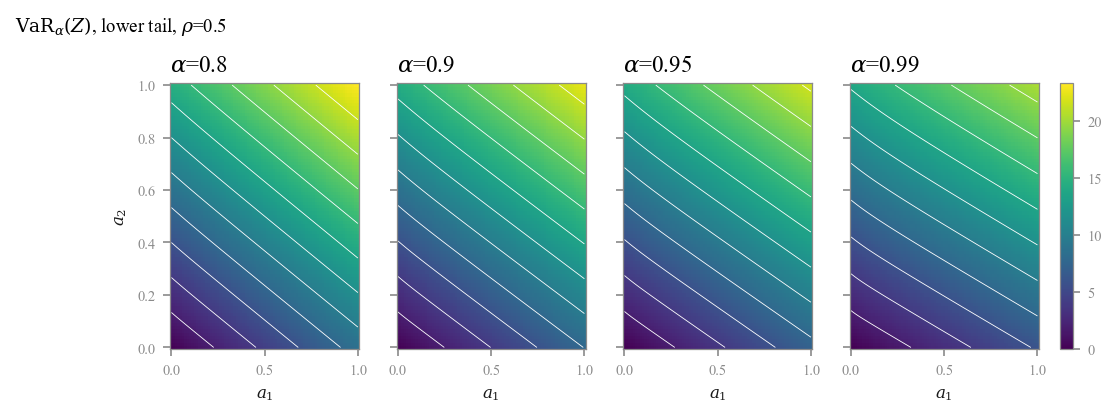

In [72]:
alphas = [0.8, 0.9, 0.95, 0.99]; n = 81
a1, a2 = np.meshgrid(np.linspace(0, 1, n), np.linspace(0, 1, n))
sd = np.sqrt(np.maximum(a1**2*s[0]**2 + a2**2*s[1]**2 + 2*rho*a1*a2*s[0]*s[1], 0))
mu_Z = a1*m[0] + a2*m[1]

V = {al: mu_Z + norm.ppf(1 - al) * sd for al in alphas}
lev = np.linspace(min(v.min() for v in V.values()), max(v.max() for v in V.values()), 13) #shared scale

fig, ax = plt.subplots(1, 4, figsize = (9, 2.3), sharey = True)
for k, al in enumerate(alphas):
    h = ax[k].pcolormesh(a1, a2, V[al], cmap = 'viridis', vmin = lev[0], vmax = lev[-1], shading = 'auto')
    ax[k].contour(a1, a2, V[al], lev, colors = 'w', linewidths = 0.4)
    ms.style_axes(ax[k], xlabel = r'$a_1$', ylabel = r'$a_2$' if k == 0 else None,
                  title = rf'$\alpha$={al}', grid = False, box = True)
fig.colorbar(h, ax = ax, pad = 0.02)
fig.suptitle(rf'$\mathrm{{VaR}}_\alpha(Z)$, lower tail, $\rho$={rho}', x = 0.01, y = 1.08, ha = 'left', fontsize = 9)

### A4. Confidence adjustment inside the unknown-dependence worst case

Marginals $X_1\sim N(10,2^2)$, $X_2\sim N(15,4^2)$; the worst case over the Frechet class is $\underline{VaR}_\varepsilon = \sup_{a+b=\varepsilon}\{F_1^{-1}(a)+F_2^{-1}(b)\}$.

In [2]:
from scipy.optimize import minimize_scalar

m = np.array([10., 15.]); s = np.array([2., 4.]); alpha = 0.9; eps = 1 - alpha
q1 = lambda p: m[0] + s[0]*norm.ppf(p)        #trusted asset, N(10, 2^2)
q2 = lambda p: m[1] + s[1]*norm.ppf(p)        #reported envelope of the low-confidence asset, N(15, 4^2)

derate = lambda p, a2: a2*q2(p)               #a2 X2 ~ N(a2 mu2, (a2 sd2)^2)
shift  = lambda p, dl: q2(p) - dl             #N(mu2 - dl, sd2^2)
inflate = lambda p, kp: m[1] + kp*s[1]*norm.ppf(p)  #N(mu2, (kp sd2)^2)

def wc(e, g2 = q2):  #Makarov sup over a+b = e, sharp for d = 2
    f = lambda t: -(q1(e*t) + g2(e*(1 - t)))
    r = minimize_scalar(f, bounds = (1e-9, 1 - 1e-9), method = 'bounded'); a = e*r.x
    return -r.fun, (q1(a), g2(e - a)), (a, e - a)

rel = lambda c: 1 - brentq(lambda e: wc(e)[0] - c, 1e-10, 0.5) #worst-case reliability of bid c under the reported marginals
eta_of = lambda t2: eps - norm.cdf((t2 - m[1])/s[1])           #reported-level budget consumed by pinning X2 at t2

var_M = q1(eps) + q2(eps)
print(f"VaR^M = {var_M:.3f}, worst-case reliability {rel(var_M):.3f}, h needed = {var_M - wc(eps)[0]:.3f}")

VaR^M = 17.311, worst-case reliability 0.814, h needed = 1.975


In [15]:
0.0297+0.0703

0.1

In [20]:
h = 2.18  #haircut on X2's P90
t2 = q2(eps) - h
a2 = t2/q2(eps); dl = h; kp = (m[1] - t2)/(-norm.ppf(eps)*s[1]) # amount of derating, shift or inflation

mth = {'derate': (a2, lambda p: derate(p, a2)), 'shift': (dl, lambda p: shift(p, dl)), 'inflate': (kp, lambda p: inflate(p, kp))}
for k, (par, g2) in mth.items():
    c, x, ab = wc(eps, g2)
    print(f"{k:8s} parameter {par:.4f} | _VaR_ {c:7.3f} at ({x[0]:.3f}, {x[1]:.3f}), (u*,v*) = ({ab[0]:.4f}, {ab[1]:.4f}) | alpha_Z {rel(c):.4f}")

derate   parameter 0.7792 | _VaR_  13.346 at (6.414, 6.932), (u*,v*) = (0.0365, 0.0635) | alpha_Z 0.9513
shift    parameter 2.1800 | _VaR_  13.155 at (6.228, 6.927), (u*,v*) = (0.0297, 0.0703) | alpha_Z 0.9547
inflate  parameter 1.4253 | _VaR_  12.884 at (5.952, 6.933), (u*,v*) = (0.0215, 0.0785) | alpha_Z 0.9593


In [21]:
eta2 = 0.05  #KS band on X2: budget subtraction, bid = wc at eps - eta2
for e2 in [eta2, eta_of(t2)]:
    c, x, ab = wc(eps - e2)
    print(f"eta2 {e2:.4f} | q_eff {q2(eps - e2):7.3f}, h_eq {q2(eps) - q2(eps - e2):.3f} | _VaR_ {c:7.3f} at ({x[0]:.3f}, {x[1]:.3f}) | alpha_Z {rel(c):.4f}")

eta2 0.0500 | q_eff   8.421, h_eq 1.453 | _VaR_  13.412 at (5.673, 7.739) | alpha_Z 0.9500
eta2 0.0661 | q_eff   7.694, h_eq 2.180 | _VaR_  12.430 at (5.380, 7.050) | alpha_Z 0.9661


In [23]:
import pandas as pd

e2 = eta_of(t2)  #the band that pins X2 at the same t2 as the h = 2.18 methods
rows = {f'band eta2={e2:.4f}': (q2(eps - e2), wc(eps - e2)[0])} | {k: (t2, wc(eps, g2)[0]) for k, (par, g2) in mth.items()}
tab = pd.DataFrame(rows, index = ['q_eff', '_VaR_worst']).T
tab['alpha_Z'] = [rel(c) for c in tab._VaR_worst]
tab['alpha_band'] = tab.alpha_Z - e2  #reliability if F2 is really eta2 worse than reported; only the band keeps P90

print(f"h = {h}, t2 = {t2:.3f}, equivalent eta2 = {e2:.4f}")
print(tab.to_string(float_format = lambda v: f'{v:.4f}'))

h = 2.18, t2 = 7.694, equivalent eta2 = 0.0661
                  q_eff  _VaR_worst  alpha_Z  alpha_band
band eta2=0.0661 7.6938     12.4304   0.9661      0.9000
derate           7.6938     13.3461   0.9513      0.8851
shift            7.6938     13.1553   0.9547      0.8886
inflate          7.6938     12.8842   0.9593      0.8932
